In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sys
from pathlib import Path

# Get project root directory
PROJECT_ROOT = Path.cwd().parent

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project Root:", PROJECT_ROOT)
print("Python Path Added Successfully!")

from src.data.ingestion import load_train_data
from src.data.validation import validate_dataset
from src.data.quality_report import generate_quality_report
from src.data.metadata import add_training_rul, create_engine_summary

train_df = load_train_data(
    data_dir=PROJECT_ROOT / "data" / "raw",
    subset="FD001",
)

train_df.head()

Project Root: c:\Users\Administrator\AI&ML Project\AuroGuard-AI
Python Path Added Successfully!


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,dataset
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,FD001
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,FD001
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,FD001
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,FD001
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,FD001


In [2]:
print("Shape:", train_df.shape)
print("Engine count:", train_df["engine_id"].nunique())
print("Columns:", train_df.columns.tolist())

train_df.info()

Shape: (20631, 27)
Engine count: 100
Columns: ['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'dataset']
<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 27 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   engine_id  20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64

In [3]:
validation_results = validate_dataset(
    train_df,
    dataset_type="train",
)

validation_results

{'dataset_type': 'train',
 'status': 'passed',
 'rows': 20631,
 'engine_count': 100,
 'columns': 27,
 'min_cycle': 1,
 'max_cycle': 362,
 'min_engine_life': 128,
 'max_engine_life': 362,
 'missing_values': 0,
 'duplicate_records': 0}

In [4]:
engine_life = (
    train_df.groupby("engine_id")["cycle"]
    .max()
)

engine_life.describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

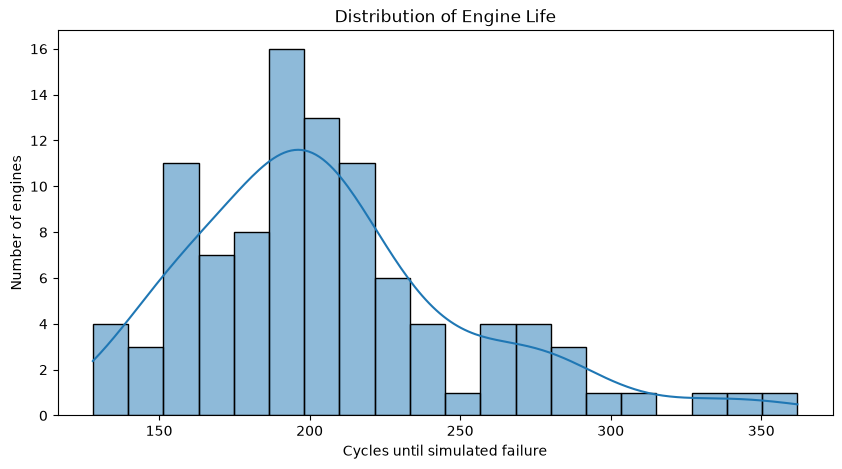

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    engine_life,
    bins=20,
    kde=True,
)

plt.title("Distribution of Engine Life")
plt.xlabel("Cycles until simulated failure")
plt.ylabel("Number of engines")

plt.show()

In [6]:
sensor_columns = [
    column
    for column in train_df.columns
    if column.startswith("sensor_")
]

sensor_stats = train_df[sensor_columns].describe().T

sensor_stats

,count,mean,std,min,25%,50%,75%,max
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200
sensor_6,20631.0,21.609803,1.388985e-03,21.6000,21.6100,21.6100,21.6100,21.6100
sensor_7,20631.0,553.367711,8.850923e-01,549.8500,552.8100,553.4400,554.0100,556.0600
sensor_8,20631.0,2388.096652,7.098548e-02,2387.9000,2388.0500,2388.0900,2388.1400,2388.5600
sensor_9,20631.0,9065.242941,2.208288e+01,9021.7300,9053.1000,9060.6600,9069.4200,9244.5900
sensor_10,20631.0,1.300000,0.000000e+00,1.3000,1.3000,1.3000,1.3000,1.3000


In [7]:
constant_sensors = [
    sensor
    for sensor in sensor_columns
    if train_df[sensor].nunique() <= 1
]

constant_sensors

['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

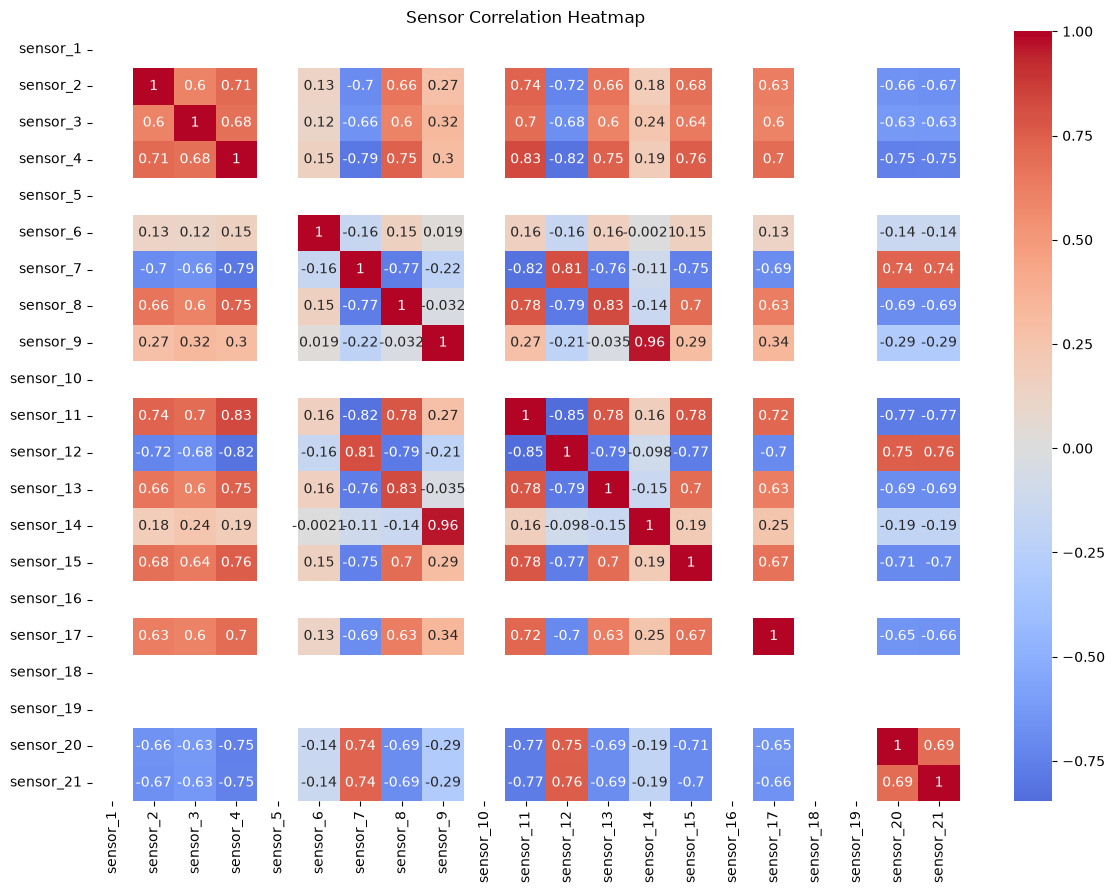

In [8]:
sensor_corr = train_df[sensor_columns].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    sensor_corr,
    cmap="coolwarm",
    center=0,
    annot=True,
)

plt.title("Sensor Correlation Heatmap")
plt.show()

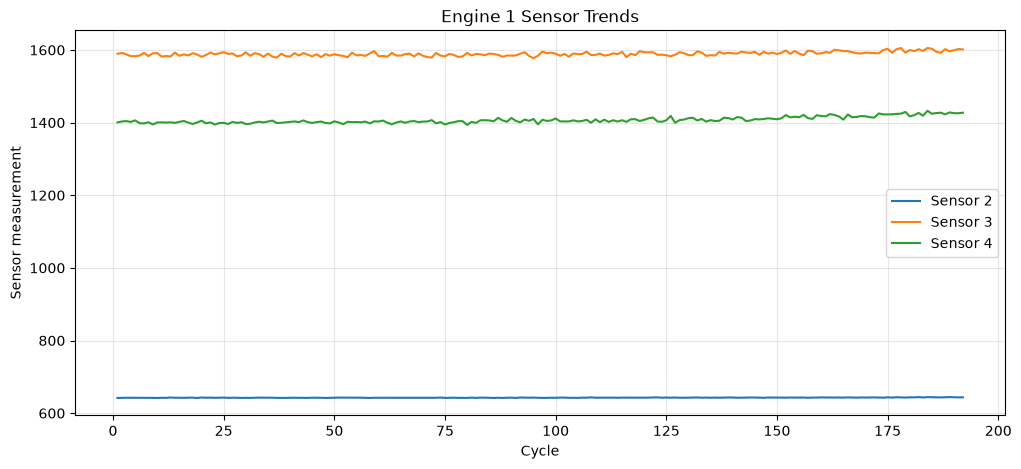

In [9]:
engine_id = 1

engine_data = train_df[
    train_df["engine_id"] == engine_id
].sort_values("cycle")

plt.figure(figsize=(12, 5))

plt.plot(
    engine_data["cycle"],
    engine_data["sensor_2"],
    label="Sensor 2",
)

plt.plot(
    engine_data["cycle"],
    engine_data["sensor_3"],
    label="Sensor 3",
)

plt.plot(
    engine_data["cycle"],
    engine_data["sensor_4"],
    label="Sensor 4",
)

plt.xlabel("Cycle")
plt.ylabel("Sensor measurement")
plt.title(f"Engine {engine_id} Sensor Trends")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [10]:
train_rul_df = add_training_rul(
    train_df
)

train_rul_df[
    train_rul_df["engine_id"] == 1
].tail(10)

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,dataset,RUL,RUL_target
182,1,183,0.0001,0.0001,100.0,518.67,643.24,1597.23,1419.03,14.62,...,8.5041,0.03,396,2388,100.0,38.56,23.1302,FD001,9,9
183,1,184,0.0004,0.0003,100.0,518.67,644.07,1605.44,1432.52,14.62,...,8.5133,0.03,395,2388,100.0,38.43,23.0146,FD001,8,8
184,1,185,0.0008,0.0001,100.0,518.67,643.80,1603.46,1424.40,14.62,...,8.4984,0.03,395,2388,100.0,38.51,23.0700,FD001,7,7
185,1,186,0.0027,-0.0003,100.0,518.67,643.51,1595.16,1426.30,14.62,...,8.5227,0.03,397,2388,100.0,38.47,23.0564,FD001,6,6
186,1,187,-0.0047,-0.0000,100.0,518.67,643.32,1592.10,1427.27,14.62,...,8.5218,0.03,396,2388,100.0,38.42,23.0822,FD001,5,5
187,1,188,-0.0067,0.0003,100.0,518.67,643.75,1602.38,1422.78,14.62,...,8.5207,0.03,396,2388,100.0,38.51,22.9588,FD001,4,4
188,1,189,-0.0006,0.0002,100.0,518.67,644.18,1596.17,1428.01,14.62,...,8.5183,0.03,395,2388,100.0,38.48,23.1127,FD001,3,3
189,1,190,-0.0027,0.0001,100.0,518.67,643.64,1599.22,1425.95,14.62,...,8.5223,0.03,398,2388,100.0,38.49,23.0675,FD001,2,2
190,1,191,-0.0000,-0.0004,100.0,518.67,643.34,1602.36,1425.77,14.62,...,8.5174,0.03,394,2388,100.0,38.45,23.1295,FD001,1,1
191,1,192,0.0009,-0.0000,100.0,518.67,643.54,1601.41,1427.20,14.62,...,8.5113,0.03,396,2388,100.0,38.48,22.9649,FD001,0,0


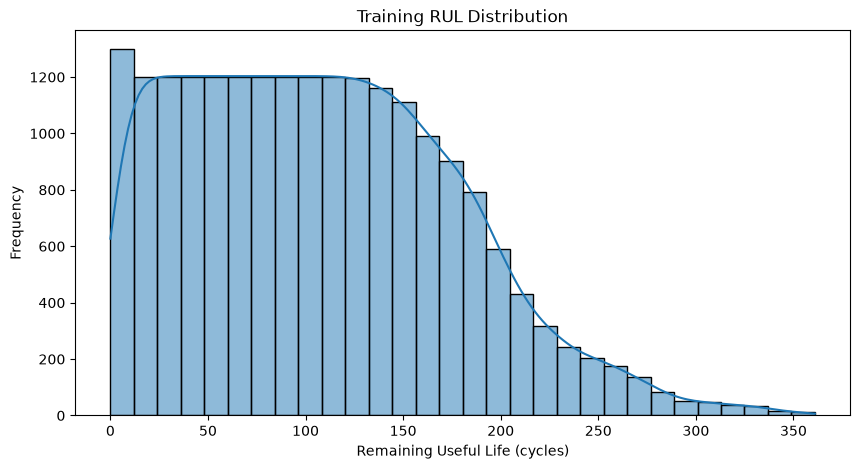

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    train_rul_df["RUL"],
    bins=30,
    kde=True,
)

plt.title("Training RUL Distribution")
plt.xlabel("Remaining Useful Life (cycles)")
plt.ylabel("Frequency")

plt.show()

In [12]:
from src.data.metadata import add_training_rul

train_df = add_training_rul(
    train_df,
    rul_cap=125,
)

train_df[
    ["engine_id", "cycle", "RUL", "RUL_target"]
].head(10)

,engine_id,cycle,RUL,RUL_target
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125
5,1,6,186,125
6,1,7,185,125
7,1,8,184,125
8,1,9,183,125
9,1,10,182,125


In [13]:
from src.features.splitting import split_by_engine

train_data, val_data = split_by_engine(
    train_df,
    validation_size=0.2,
    random_state=42,
)

print("Training engines:", train_data["engine_id"].nunique())
print("Validation engines:", val_data["engine_id"].nunique())

Training engines: 80
Validation engines: 20


In [14]:
from src.features.selection import (
    select_variable_sensors,
    get_sensor_variance,
)

sensor_variance = get_sensor_variance(train_data)

print(sensor_variance)

selected_sensors = select_variable_sensors(
    train_data
)

print("Selected sensors:", selected_sensors)
print("Number selected:", len(selected_sensors))

       sensor      variance
0    sensor_9  5.134666e+02
1   sensor_14  3.836538e+02
2    sensor_4  8.038227e+01
3    sensor_3  3.703220e+01
4   sensor_17  2.391097e+00
5    sensor_7  7.704836e-01
6   sensor_12  5.402105e-01
7    sensor_2  2.481278e-01
8   sensor_11  7.061425e-02
9   sensor_20  3.235409e-02
10  sensor_21  1.153588e-02
11  sensor_13  5.142130e-03
12   sensor_8  4.991014e-03
13  sensor_15  1.406858e-03
14   sensor_6  1.860184e-06
15   sensor_5  2.840071e-29
16  sensor_10  4.930678e-32
17  sensor_16  1.083401e-34
18   sensor_1  0.000000e+00
19  sensor_19  0.000000e+00
20  sensor_18  0.000000e+00
Selected sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Number selected: 15


In [15]:
import pandas as pd

X_train = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "X_train_FD001.csv"
)

X_val = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "X_val_FD001.csv"
)

y_train = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "y_train_FD001.csv"
)

y_val = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "y_val_FD001.csv"
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

print("Training targets:", y_train.shape)
print("Validation targets:", y_val.shape)

print("Missing values:", X_train.isna().sum().sum())
print("Infinite values:", X_train.isin([float("inf"), float("-inf")]).sum().sum())

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert list(X_train.columns) == list(X_val.columns)

print("All checks passed!")

Training: (16561, 130)
Validation: (4070, 130)
Training targets: (16561, 1)
Validation targets: (4070, 1)
Missing values: 0
Infinite values: 0
All checks passed!


In [17]:
from src.evaluation.metrics import nasa_score

actual = [100, 100, 100]
predicted = [90, 110, 130]

print(nasa_score(actual, predicted))

21.96192428559516
